# DINOv2 ViT-B/14 — Diabetic Retinopathy Grading
**EEEM068 Applied Machine Learning — University of Surrey**

| Setting | Value |
|---|---|
| Architecture | DINOv2 ViT-B/14 (`facebookresearch/dinov2`) |
| Pre-training | Self-supervised DINO on LVD-142M (Meta AI) |
| Input size | 378×378 px  (patch-14 multiple: 27×14=378) |
| Normalisation | ImageNet RGB mean/std |
| Loss | FocalLoss γ=2 + class-weight alpha (Exp1+) |
| Sampler | WeightedRandomSampler (Exp1+) |
| Optimiser | AdamW — differential LR (backbone 1e-5, head 1e-4) |
| Scheduler | CosineAnnealingLR |
| Primary Metric | **Macro F1** (team-agreed) |
| Secondary Metrics | QWK, Weighted F1, Precision, Recall, mAP, AUC-ROC, Top-1 Acc |
| Best model saved by | Val **Macro F1** |
| Platform | Surrey AI Supercomputer |

---
**Sections 1–10:** Baseline (CE loss, shuffle sampler, standard augmentation)  
**Section 11:** Exp 1 — Imbalance Handling (WRS + FocalLoss)  
**Section 12:** Exp 2 — Enhanced Augmentation  
**Section 13:** Exp 3 — Two-Phase Freeze→Unfreeze Fine-tuning  
**Section 14:** Exp 4 — Majority-Class Downsampling  
**Section 15:** Exp 5 — DINOv2 Attention Maps + Fine-tuning Depth  
**Section 16:** Full Cross-Experiment Comparison Table


## 1. Imports

In [1]:
import os, gc
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'

import os, random
from pathlib import Path
from copy import deepcopy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report, cohen_kappa_score, confusion_matrix,
    f1_score, accuracy_score, precision_score, recall_score,
    average_precision_score, roc_auc_score
)
from sklearn.preprocessing import label_binarize

print(f'PyTorch : {torch.__version__}')
print(f'CUDA    : {torch.cuda.is_available()}')

/scratch/AML Priyanka/AML_G14_CW/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch : 2.11.0+cu130
CUDA    : True


## 2. Configuration

NEED TO BE CHANGED 

In [2]:
# ── Paths — matches data_preprocessing.ipynb exactly ─────────────────────────
NOTEBOOK_DIR    = Path().resolve()
ROOT            = NOTEBOOK_DIR.parent

DATA_ROOT       = ROOT / 'data' / 'diabetic-retinopathy-detection'
TRAIN_DIR       = DATA_ROOT / 'train_proc'         # 13-stage preprocessed images
VAL_DIR         = DATA_ROOT / 'val_proc'
TEST_LABELS_DIR = DATA_ROOT / 'test_labels_proc'
TRAIN_CSV       = DATA_ROOT / 'train_split.csv'
VAL_CSV         = DATA_ROOT / 'val_split.csv'
TEST_CSV        = DATA_ROOT / 'test_split.csv'

OUT_DIR     = ROOT / 'outputs' / 'dinov2'
CKPT_DIR    = OUT_DIR / 'checkpoints'
FIGURES_DIR = OUT_DIR / 'figures'
for d in (OUT_DIR, CKPT_DIR, FIGURES_DIR):
    d.mkdir(parents=True, exist_ok=True)

EXPERIMENT_NAME = 'dinov2'

# ── Reproducibility ───────────────────────────────────────────────────────────
SEED = 42

# ── Data ──────────────────────────────────────────────────────────────────────
# Images are 380x380 from Notebook 1.
# DINOv2 ViT-B/14 patch size = 14px.  378 = 27*14 is the closest valid multiple.
IMAGE_SIZE  = 224   # 378 causes OOM on 16GB GPU with desktop running
NUM_CLASSES = 5
CLASS_NAMES = ['No DR', 'Mild', 'Moderate', 'Severe', 'Proliferative']

# DINOv2 pretrained on LVD-142M (diverse web images) → ImageNet RGB normalisation
DINOV2_MEAN = (0.485, 0.456, 0.406)
DINOV2_STD  = (0.229, 0.224, 0.225)

# ── Training ──────────────────────────────────────────────────────────────────
BATCH_SIZE              = 8   # safe for 16GB GPU + desktop overhead    # reduced from 32 — ViT-B/14 at 378px needs ~1.8GB/batch
NUM_WORKERS             = 2
EPOCHS                  = 10
LR_HEAD                 = 1e-4    # classification head
LR_BACKBONE             = 1e-5    # pretrained backbone — 10x lower to prevent forgetting
WEIGHT_DECAY            = 1e-2
EARLY_STOPPING_PATIENCE = 7

print('Config set. Root:', ROOT)
print(f'Images : {TRAIN_DIR.name} / {VAL_DIR.name} / {TEST_LABELS_DIR.name}')
print(f'Input  : {IMAGE_SIZE}x{IMAGE_SIZE}px')
print(f'Batch  : {BATCH_SIZE}')

Config set. Root: /scratch/AML Priyanka/AML_G14_CW
Images : train_proc / val_proc / test_labels_proc
Input  : 224x224px
Batch  : 8


In [3]:
def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

# Clean up any leftover GPU memory from previous crashed runs
gc.collect()
torch.cuda.empty_cache()

set_seed(SEED)
device  = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
use_amp = device.type == 'cuda'

if torch.cuda.is_available():
    total = torch.cuda.get_device_properties(0).total_memory / 1e9
    used  = torch.cuda.memory_allocated() / 1e9
    free  = total - used
    print(f'Device : {device}  AMP={use_amp}')
    print(f'GPU    : {torch.cuda.get_device_name(0)}')
    print(f'VRAM   : {total:.1f} GB total | {used:.2f} GB used | {free:.2f} GB free')
    if free < 12.0:
        print('WARNING: < 12 GB free — kill desktop apps or other GPU processes first')
        print('  In terminal: nvidia-smi  then  kill -9 <stale python PID>')
else:
    print('Device:', device, '  AMP:', use_amp)

Device : cuda  AMP=True
GPU    : NVIDIA RTX A4000
VRAM   : 16.7 GB total | 0.00 GB used | 16.74 GB free


In [4]:
# ── Checkpoint registry — defined once, reused by every eval cell ─────────────
# Run this cell after a kernel restart to resume evaluation without retraining.
CKPT_BASELINE = CKPT_DIR / f'{EXPERIMENT_NAME}_best.pt'
CKPT_EXP1     = ROOT / 'outputs' / 'dinov2_exp1' / 'checkpoints' / 'dinov2_exp1_best.pt'
CKPT_EXP2     = ROOT / 'outputs' / 'dinov2_exp2' / 'checkpoints' / 'dinov2_exp2_best.pt'
CKPT_EXP3_P1  = ROOT / 'outputs' / 'dinov2_exp3' / 'checkpoints' / 'dinov2_exp3_phase1_best.pt'
CKPT_EXP3     = ROOT / 'outputs' / 'dinov2_exp3' / 'checkpoints' / 'dinov2_exp3_best.pt'
CKPT_EXP4     = ROOT / 'outputs' / 'dinov2_exp4' / 'checkpoints' / 'dinov2_exp4_best.pt'
CKPT_EXP5_A   = ROOT / 'outputs' / 'dinov2_exp5' / 'checkpoints' / 'dinov2_exp5_headonly_best.pt'
CKPT_EXP5_B   = ROOT / 'outputs' / 'dinov2_exp5' / 'checkpoints' / 'dinov2_exp5_last3_best.pt'
CKPT_EXP5_C   = ROOT / 'outputs' / 'dinov2_exp5' / 'checkpoints' / 'dinov2_exp5_last6_best.pt'
CKPT_EXP5_D   = ROOT / 'outputs' / 'dinov2_exp5' / 'checkpoints' / 'dinov2_exp5_allblocks_best.pt'

print('Checkpoint registry:')
for label, path in [
    ('Baseline',      CKPT_BASELINE),
    ('Exp1',          CKPT_EXP1),
    ('Exp2',          CKPT_EXP2),
    ('Exp3 Phase1',   CKPT_EXP3_P1),
    ('Exp3',          CKPT_EXP3),
    ('Exp4',          CKPT_EXP4),
    ('Exp5-HeadOnly', CKPT_EXP5_A),
    ('Exp5-Last3',    CKPT_EXP5_B),
    ('Exp5-Last6',    CKPT_EXP5_C),
    ('Exp5-AllBlocks',CKPT_EXP5_D),
]:
    status = 'saved' if path.exists() else 'not yet trained'
    print(f'  {label:<16}: {status}')

Checkpoint registry:
  Baseline        : saved
  Exp1            : not yet trained
  Exp2            : not yet trained
  Exp3 Phase1     : not yet trained
  Exp3            : not yet trained
  Exp4            : not yet trained
  Exp5-HeadOnly   : not yet trained
  Exp5-Last3      : not yet trained
  Exp5-Last6      : not yet trained
  Exp5-AllBlocks  : not yet trained


## 3. Load Pre-Split Data

In [5]:
train_df = pd.read_csv(TRAIN_CSV)
val_df   = pd.read_csv(VAL_CSV)
test_df  = pd.read_csv(TEST_CSV)

print(f'Train : {len(train_df):,}  Val : {len(val_df):,}  Test : {len(test_df):,}')
print()
print(f'{"Grade":<6} {"Name":<18} {"Train":>7} {"Val":>6} {"Test":>6}')
print('-'*47)
for g, name in enumerate(CLASS_NAMES):
    t = (train_df['level']==g).sum()
    v = (val_df['level']==g).sum()
    s = (test_df['level']==g).sum()
    print(f'  {g}    {name:<18} {t:>6,}  {v:>5,}  {s:>5,}')

Train : 24,588  Val : 5,269  Test : 5,269

Grade  Name                 Train    Val   Test
-----------------------------------------------
  0    No DR              18,067  3,871  3,872
  1    Mild                1,710    367    366
  2    Moderate            3,704    794    794
  3    Severe                611    131    131
  4    Proliferative         496    106    106


## 4. Dataset and DataLoaders

In [6]:
class DRDataset(Dataset):
    """Fundus image dataset. Reads from data_dir using the 'image' column."""
    def __init__(self, df: pd.DataFrame, data_dir: Path, transform=None):
        self.df       = df.reset_index(drop=True)
        self.data_dir = Path(data_dir)
        self.transform = transform
    def __len__(self): return len(self.df)
    def __getitem__(self, idx):
        row   = self.df.iloc[idx]
        image = Image.open(self.data_dir / f"{row['image']}.jpeg").convert('RGB')
        label = int(row['level'])
        if self.transform: image = self.transform(image)
        return image, label


# Baseline transforms — minimal augmentation (matching Mahad's baseline)
train_transform = transforms.Compose([
    transforms.Resize(int(IMAGE_SIZE * 1.05)),
    transforms.RandomCrop(IMAGE_SIZE),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(DINOV2_MEAN, DINOV2_STD),
])
val_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(DINOV2_MEAN, DINOV2_STD),
])

train_ds = DRDataset(train_df, TRAIN_DIR,       transform=train_transform)
val_ds   = DRDataset(val_df,   VAL_DIR,         transform=val_transform)
test_ds  = DRDataset(test_df,  TEST_LABELS_DIR, transform=val_transform)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=True, drop_last=True,
                          persistent_workers=False)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE*2, shuffle=False,  # 2x — no grads
                          num_workers=NUM_WORKERS, pin_memory=True,
                          persistent_workers=False)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE*2, shuffle=False,  # 2x — no grads
                          num_workers=NUM_WORKERS, pin_memory=True,
                          persistent_workers=False)

print(f'Train loader: {len(train_loader)} batches/epoch')
print(f'Val loader  : {len(val_loader)} batches/epoch')
print(f'Test loader : {len(test_loader)} batches/epoch')

Train loader: 3073 batches/epoch
Val loader  : 330 batches/epoch
Test loader : 330 batches/epoch


## 5. Model
`dinov2_vitb14` — self-supervised on LVD-142M, 768-dim CLS token.  
Custom head: Linear(768→512) → ReLU → Dropout → Linear(512→5).

In [7]:
import os
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'

from torch.utils.checkpoint import checkpoint as grad_ckpt

class DINOv2Classifier(nn.Module):
    """
    DINOv2 ViT-B/14 with custom 5-class head for DR grading.

    Args:
        freeze_backbone  : freeze entire backbone (head-only training)
        unfreeze_blocks  : unfreeze last N transformer blocks (-1 = all)
        dropout          : dropout rate in classification head
        grad_checkpoint  : recompute block activations in backward to save ~10 GB of VRAM
    """
    def __init__(self, freeze_backbone=False, unfreeze_blocks=-1, dropout=0.3, grad_checkpoint=True):
        super().__init__()
        self.backbone = torch.hub.load(
            'facebookresearch/dinov2', 'dinov2_vitb14', pretrained=True
        )
        # Step 1 — freeze all backbone params
        for p in self.backbone.parameters():
            p.requires_grad = False
        # Step 2 — selectively unfreeze
        if not freeze_backbone:
            if unfreeze_blocks == -1:
                for p in self.backbone.parameters(): p.requires_grad = True
            elif unfreeze_blocks > 0:
                for blk in list(self.backbone.blocks)[-unfreeze_blocks:]:
                    for p in blk.parameters(): p.requires_grad = True
                for p in self.backbone.norm.parameters(): p.requires_grad = True

        # Step 3 — wrap each ViT block with gradient checkpointing
        # Recomputes activations during backward instead of storing them → saves ~10 GB
        if grad_checkpoint:
            for blk in self.backbone.blocks:
                orig_fwd = blk.forward
                def make_ckpt_fwd(fn):
                    def ckpt_fwd(x):
                        return grad_ckpt(fn, x, use_reentrant=False)
                    return ckpt_fwd
                blk.forward = make_ckpt_fwd(orig_fwd)

        # Classification head
        in_f = self.backbone.embed_dim   # 768
        self.classifier = nn.Sequential(
            nn.Linear(in_f, 512), nn.ReLU(), nn.Dropout(p=dropout), nn.Linear(512, NUM_CLASSES)
        )
        for m in self.classifier.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight); nn.init.zeros_(m.bias)

    def forward(self, x): return self.classifier(self.backbone(x))

    def get_attention_maps(self, x): return self.backbone.get_last_selfattention(x)

    def param_groups(self, lr_bb, lr_head, wd):
        """Differential learning-rate param groups."""
        return [
            {'params':[p for p in self.backbone.parameters()   if p.requires_grad], 'lr':lr_bb,   'weight_decay':wd},
            {'params':[p for p in self.classifier.parameters() if p.requires_grad], 'lr':lr_head, 'weight_decay':wd},
        ]


# Free GPU before loading 86M param model
gc.collect()
torch.cuda.empty_cache()

model = DINOv2Classifier().to(device)
total     = sum(p.numel() for p in model.parameters())
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Model            : DINOv2 ViT-B/14  (full fine-tune + grad checkpointing)')
print(f'Total params     : {total:,}')
print(f'Trainable params : {trainable:,}')
print(f'Classifier head  : {model.classifier}')
mem = torch.cuda.memory_allocated()/1e9
print(f'VRAM after model load: {mem:.2f} GB  (budget left: {torch.cuda.get_device_properties(0).total_memory/1e9 - mem:.2f} GB)')


Using cache found in /user/HS402/pc01093/.cache/torch/hub/facebookresearch_dinov2_main
/user/HS402/pc01093/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/user/HS402/pc01093/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/user/HS402/pc01093/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Model            : DINOv2 ViT-B/14  (full fine-tune + grad checkpointing)
Total params     : 86,976,773
Trainable params : 86,976,773
Classifier head  : Sequential(
  (0): Linear(in_features=768, out_features=512, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.3, inplace=False)
  (3): Linear(in_features=512, out_features=5, bias=True)
)
VRAM after model load: 0.35 GB  (budget left: 16.39 GB)


## 6. Loss, Optimiser, Scheduler
Baseline: plain CrossEntropy, no class weights — identical conditions to EfficientNet baseline.

In [8]:
criterion = nn.CrossEntropyLoss()   # baseline — no weights
optimizer = torch.optim.AdamW(
    model.param_groups(LR_BACKBONE, LR_HEAD, WEIGHT_DECAY)
)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

print('Loss      :', criterion)
print(f'Optimiser : AdamW  backbone_lr={LR_BACKBONE}  head_lr={LR_HEAD}')
print('Scheduler :', scheduler.__class__.__name__)

Loss      : CrossEntropyLoss()
Optimiser : AdamW  backbone_lr=1e-05  head_lr=0.0001
Scheduler : CosineAnnealingLR


## 7. Training Loop

In [9]:
scaler = torch.amp.GradScaler('cuda', enabled=use_amp)


def run_epoch(mdl, ldr, crit, opt, train_mode: bool, scl=None):
    """
    Run one epoch with optional AMP.
    Returns: avg_loss, all_labels, all_preds, all_probs
    """
    mdl.train(train_mode)
    total_loss, total = 0.0, 0
    all_preds, all_labels, all_probs = [], [], []

    ctx = torch.enable_grad() if train_mode else torch.no_grad()
    with ctx:
        for images, labels in tqdm(ldr, leave=False, desc='train' if train_mode else 'val '):
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.autocast(device_type='cuda', enabled=use_amp):
                logits = mdl(images)
                loss   = crit(logits, labels)

            if train_mode and opt is not None:
                opt.zero_grad(set_to_none=True)
                if use_amp and scl is not None:
                    scl.scale(loss).backward()
                    scl.unscale_(opt)
                    nn.utils.clip_grad_norm_(mdl.parameters(), 1.0)
                    scl.step(opt); scl.update()
                else:
                    loss.backward()
                    nn.utils.clip_grad_norm_(mdl.parameters(), 1.0)
                    opt.step()

            total_loss += loss.item() * labels.size(0)
            total      += labels.size(0)
            probs = torch.softmax(logits.detach(), dim=1)
            preds = logits.detach().argmax(dim=1)
            all_preds.extend(preds.cpu().tolist())
            all_labels.extend(labels.cpu().tolist())
            all_probs.extend(probs.cpu().numpy())

    # Free cached (but unused) GPU memory after each pass
    torch.cuda.empty_cache()
    return total_loss / total, all_labels, all_preds, np.array(all_probs)


print('run_epoch defined  (AMP={}).'.format(use_amp))


run_epoch defined  (AMP=True).


In [10]:
# ── Dependency check — run Sections 1-7 before this cell ─────────────────
assert 'model'     in dir(), 'Run Section 5 (Model) first'
assert 'optimizer' in dir(), 'Run Section 6 (Loss/Optimiser) first'
assert 'scaler'    in dir(), 'Run Section 7 (Training Loop) first'
assert 'train_loader' in dir(), 'Run Section 4 (DataLoaders) first'

best_path         = CKPT_BASELINE
best_val_macro_f1 = 0.0
patience_left     = EARLY_STOPPING_PATIENCE
history = {'train_loss':[], 'val_loss':[], 'train_acc':[], 'val_acc':[], 'val_f1':[]}

print(f"{'Epoch':<8} {'Tr Loss':>10} {'Tr Acc':>8} {'Val Loss':>10} {'Val Acc':>8} {'Val F1':>8}")
print('─'*60)

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_labels, tr_preds, _ = run_epoch(model, train_loader, criterion, optimizer, True,  scaler)
    torch.cuda.empty_cache()   # flush train activations before val pass
    vl_loss, vl_labels, vl_preds, _ = run_epoch(model, val_loader,   criterion, None,      False)
    scheduler.step()

    tr_acc   = accuracy_score(tr_labels, tr_preds)
    vl_acc   = accuracy_score(vl_labels, vl_preds)
    vl_macro = f1_score(vl_labels, vl_preds, average='macro', zero_division=0)

    history['train_loss'].append(tr_loss)
    history['val_loss'].append(vl_loss)
    history['train_acc'].append(tr_acc)
    history['val_acc'].append(vl_acc)
    history['val_f1'].append(vl_macro)

    marker = ''
    # Save by Macro F1 (primary metric) — not val loss
    if vl_macro > best_val_macro_f1 + 1e-4:
        best_val_macro_f1 = vl_macro
        patience_left     = EARLY_STOPPING_PATIENCE
        torch.save({'epoch':epoch, 'model_state':model.state_dict(),
                    'val_macro_f1':vl_macro, 'val_loss':vl_loss}, best_path)
        marker = '  ← best'
    else:
        patience_left -= 1

    print(f'{epoch:<8} {tr_loss:>10.4f} {tr_acc:>8.4f} {vl_loss:>10.4f} {vl_acc:>8.4f} {vl_macro:>8.4f}{marker}')

    if patience_left == 0:
        print(f'\nEarly stopping at epoch {epoch}.')
        break

print(f'\nBest Val Macro F1: {best_val_macro_f1:.4f}  →  {best_path}')

Epoch       Tr Loss   Tr Acc   Val Loss  Val Acc   Val F1
────────────────────────────────────────────────────────────


1            0.8249   0.7413     0.7347   0.7622   0.3694  ← best


2            0.7310   0.7668     0.6863   0.7732   0.4031  ← best


3            0.7017   0.7781     0.6902   0.7812   0.3790


4            0.6695   0.7898     0.6884   0.7831   0.4429  ← best


...

6            0.6181   0.8107     0.6847   0.7905   0.4475


7            0.5888   0.8198     0.7094   0.7994   0.4814  ← best


8            0.5653   0.8276     0.6473   0.7990   0.5005  ← best


9            0.5426   0.8355     0.6444   0.8062   0.5115  ← best


10           0.5251   0.8404     0.6576   0.8060   0.5136  ← best

Best Val Macro F1: 0.5136  →  /scratch/AML Priyanka/AML_G14_CW/outputs/dinov2/checkpoints/dinov2_best.pt


## 8. Loss Curve

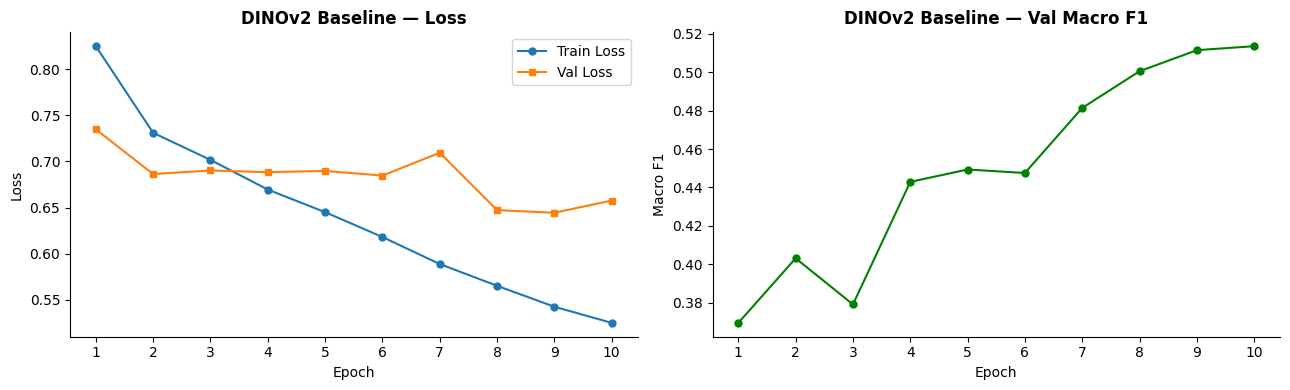

Saved → /scratch/AML Priyanka/AML_G14_CW/outputs/dinov2/figures/dinov2_loss_curve.png


In [11]:
epochs_ran = range(1, len(history['train_loss']) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(epochs_ran, history['train_loss'], label='Train Loss', marker='o', markersize=5)
axes[0].plot(epochs_ran, history['val_loss'],   label='Val Loss',   marker='s', markersize=5)
axes[0].set_title('DINOv2 Baseline — Loss', fontweight='bold')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
axes[0].legend(); axes[0].spines[['top','right']].set_visible(False)

axes[1].plot(epochs_ran, history['val_f1'], color='green', marker='o', markersize=5)
axes[1].set_title('DINOv2 Baseline — Val Macro F1', fontweight='bold')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Macro F1')
axes[1].xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
axes[1].spines[['top','right']].set_visible(False)

plt.tight_layout()
fig.savefig(FIGURES_DIR / f'{EXPERIMENT_NAME}_loss_curve.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved → {FIGURES_DIR}/{EXPERIMENT_NAME}_loss_curve.png')

## 9. Evaluation on Test Set

In [12]:
# ── Independent of training — requires Sections 1–7 + checkpoint registry ─────
_prev_model     = globals().get('model',     None)
_prev_criterion = globals().get('criterion', None)
_prev_optimizer = globals().get('optimizer', None)
_prev_scaler    = globals().get('scaler',    None)

model     = DINOv2Classifier().to(device)
criterion = nn.CrossEntropyLoss()

ckpt = torch.load(CKPT_BASELINE, map_location=device, weights_only=False)
model.load_state_dict(ckpt['model_state'])
print(f'Loaded: {CKPT_BASELINE.name}')
print(f'epoch={ckpt["epoch"]}  val_macro_f1={ckpt["val_macro_f1"]:.4f}')

_, y_true, y_pred, y_probs = run_epoch(model, test_loader, criterion, None, False)

print('\nClassification Report (Test Set):')
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=3))

if _prev_model is not None:
    model = _prev_model; criterion = _prev_criterion
    optimizer = _prev_optimizer; scaler = _prev_scaler

Using cache found in /user/HS402/pc01093/.cache/torch/hub/facebookresearch_dinov2_main


Loaded: dinov2_best.pt
epoch=10  val_macro_f1=0.5136



Classification Report (Test Set):
               precision    recall  f1-score   support

        No DR      0.847     0.962     0.901      3872
         Mild      0.250     0.011     0.021       366
     Moderate      0.612     0.521     0.563       794
       Severe      0.511     0.351     0.416       131
Proliferative      0.727     0.604     0.660       106

     accuracy                          0.807      5269
    macro avg      0.589     0.490     0.512      5269
 weighted avg      0.759     0.807     0.772      5269



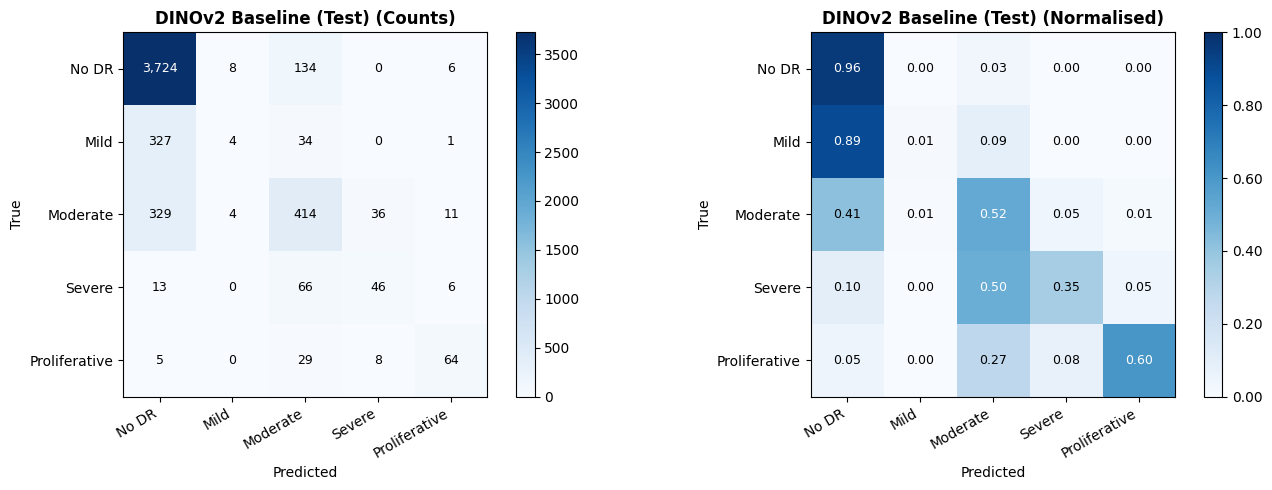

Saved → /scratch/AML Priyanka/AML_G14_CW/outputs/dinov2/figures/dinov2_confusion_matrix.png


In [13]:
def plot_confusion_matrix(y_true, y_pred, title, save_path, cmap='Blues'):
    """Plot raw + normalised confusion matrices side by side."""
    cm      = confusion_matrix(y_true, y_pred)
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for ax, data, fmt, t in [
        (axes[0], cm,      'd',   'Counts'),
        (axes[1], cm_norm, '.2f', 'Normalised')
    ]:
        im = ax.imshow(data, interpolation='nearest', cmap=cmap,
                       vmin=0, vmax=(1 if fmt=='.2f' else None))
        fig.colorbar(im, ax=ax, format=('%.2f' if fmt=='.2f' else None))
        ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right')
        ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
        ax.set_xlabel('Predicted'); ax.set_ylabel('True')
        ax.set_title(f'{title} ({t})', fontweight='bold')
        thresh = (0.5 if fmt=='.2f' else data.max()/2)
        for i in range(data.shape[0]):
            for j in range(data.shape[1]):
                val = f'{data[i,j]:.2f}' if fmt=='.2f' else f'{data[i,j]:,}'
                ax.text(j, i, val, ha='center', va='center', fontsize=9,
                        color='white' if data[i,j]>thresh else 'black')
    plt.tight_layout()
    fig.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Saved → {save_path}')

plot_confusion_matrix(y_true, y_pred, 'DINOv2 Baseline (Test)',
                      FIGURES_DIR/f'{EXPERIMENT_NAME}_confusion_matrix.png')

## 10. Baseline Results Summary

In [14]:
def full_metrics(y_true, y_pred, y_probs, label):
    """Print and return full metric set."""
    bins     = label_binarize(y_true, classes=list(range(NUM_CLASSES)))
    macro_f1 = f1_score(y_true, y_pred, average='macro',    zero_division=0)
    wt_f1    = f1_score(y_true, y_pred, average='weighted', zero_division=0)
    f1_per   = f1_score(y_true, y_pred, average=None,       zero_division=0)
    prec     = precision_score(y_true, y_pred, average='macro', zero_division=0)
    rec      = recall_score(y_true, y_pred,    average='macro', zero_division=0)
    acc      = accuracy_score(y_true, y_pred)
    qwk      = cohen_kappa_score(y_true, y_pred, weights='quadratic')
    try:
        mAP  = average_precision_score(bins, y_probs, average='macro')
        auc  = roc_auc_score(bins, y_probs, average='macro', multi_class='ovr')
    except Exception:
        mAP = auc = float('nan')

    print(f'\n{"="*54}')
    print(f'  {label}')
    print(f'{"="*54}')
    print(f'  Macro F1   (PRIMARY) : {macro_f1:.4f}')
    print(f'  QWK                  : {qwk:.4f}')
    print(f'  Weighted F1          : {wt_f1:.4f}')
    print(f'  Precision (macro)    : {prec:.4f}')
    print(f'  Recall (macro)       : {rec:.4f}')
    print(f'  mAP                  : {mAP:.4f}')
    print(f'  Mean AUC-ROC         : {auc:.4f}')
    print(f'  Top-1 Accuracy       : {acc:.4f}')
    print(f'  {"-"*52}')
    print(f'  Per-class F1:')
    for name, v in zip(CLASS_NAMES, f1_per): print(f'    {name:<20}: {v:.4f}')
    print(f'{"="*54}')
    return {'label':label,'macro_f1':macro_f1,'qwk':qwk,'wt_f1':wt_f1,
            'prec':prec,'rec':rec,'mAP':mAP,'auc':auc,'acc':acc,'f1_per':list(f1_per)}

baseline_metrics = full_metrics(y_true, y_pred, y_probs, 'DINOv2 Baseline (Test)')
qwk     = baseline_metrics['qwk']
acc     = baseline_metrics['acc']
f1_per  = baseline_metrics['f1_per']
macro_f1= baseline_metrics['macro_f1']


  DINOv2 Baseline (Test)
  Macro F1   (PRIMARY) : 0.5121
  QWK                  : 0.6974
  Weighted F1          : 0.7717
  Precision (macro)    : 0.5893
  Recall (macro)       : 0.4898
  mAP                  : 0.5609
  Mean AUC-ROC         : 0.8603
  Top-1 Accuracy       : 0.8070
  ----------------------------------------------------
  Per-class F1:
    No DR               : 0.9006
    Mild                : 0.0209
    Moderate            : 0.5629
    Severe              : 0.4163
    Proliferative       : 0.6598


## 11. Experiment 1 — Class Imbalance Handling
**Hypothesis:** The 36× imbalance biases the baseline toward majority classes.
Combining three techniques should improve Macro F1 on minority grades.

| Technique | Where | What it does |
|---|---|---|
| `WeightedRandomSampler` | Data pipeline | Over-samples minority grades per epoch |
| Class-weight alpha (α) | Loss | Scales per-class CE loss by inverse frequency |
| `FocalLoss` (γ=2) | Loss | Down-weights easy examples, focuses on hard minority samples |

> Sections 1–10 must be run first. Reuses `run_epoch`, `train_ds`, `val_loader`, `test_loader`.

In [15]:
import torch.nn.functional as F
from sklearn.utils.class_weight import compute_class_weight

class FocalLoss(nn.Module):
    """
    Focal Loss with per-class alpha weighting.
    alpha : Tensor[NUM_CLASSES] — balanced inverse-freq class weights.
    gamma : focusing parameter; (1-pt)^gamma down-weights easy examples.
    """
    def __init__(self, alpha: torch.Tensor, gamma: float = 2.0):
        super().__init__()
        self.register_buffer('alpha', alpha)   # moves with .to(device), saved in state_dict
        self.gamma = gamma
    def forward(self, logits, targets):
        ce = F.cross_entropy(logits, targets, weight=self.alpha, reduction='none')
        pt = torch.exp(-ce)
        return ((1.0 - pt) ** self.gamma * ce).mean()

# Balanced inverse-frequency weights (sklearn method)
train_labels_np  = train_df['level'].values
class_weights_np = compute_class_weight('balanced', classes=np.arange(NUM_CLASSES), y=train_labels_np)
class_weights_t  = torch.tensor(class_weights_np, dtype=torch.float32).to(device)

print('Class weights (balanced):')
for name, w in zip(CLASS_NAMES, class_weights_np): print(f'  {name:<20}: {w:.4f}')

# WeightedRandomSampler
sample_weights  = torch.as_tensor(class_weights_np[train_labels_np], dtype=torch.double)
exp1_sampler    = WeightedRandomSampler(sample_weights, len(sample_weights), replacement=True)
exp1_train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, sampler=exp1_sampler,
    num_workers=NUM_WORKERS, pin_memory=True, drop_last=True,
    persistent_workers=NUM_WORKERS>0
)
print(f'\nExp1 train loader : {len(exp1_train_loader)} batches/epoch')

Class weights (balanced):
  No DR               : 0.2722
  Mild                : 2.8758
  Moderate            : 1.3276
  Severe              : 8.0484
  Proliferative       : 9.9145

Exp1 train loader : 3073 batches/epoch


In [16]:
set_seed(SEED)
exp1_model     = DINOv2Classifier().to(device)
exp1_criterion = FocalLoss(alpha=class_weights_t, gamma=2.0)
exp1_optimizer = torch.optim.AdamW(exp1_model.param_groups(LR_BACKBONE, LR_HEAD, WEIGHT_DECAY))
exp1_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(exp1_optimizer, T_max=EPOCHS)
exp1_scaler    = torch.amp.GradScaler('cuda', enabled=use_amp)

EXP1_OUT_DIR  = ROOT / 'outputs' / 'dinov2_exp1'
EXP1_CKPT_DIR = EXP1_OUT_DIR / 'checkpoints'
EXP1_FIG_DIR  = EXP1_OUT_DIR / 'figures'
for d in (EXP1_CKPT_DIR, EXP1_FIG_DIR): d.mkdir(parents=True, exist_ok=True)
EXP1_BEST_PATH = EXP1_CKPT_DIR / 'dinov2_exp1_best.pt'

print('Exp1 model ready.')
print('Loss      : FocalLoss(gamma=2.0, alpha=balanced_class_weights)')
print('Sampler   : WeightedRandomSampler')
print(f'Checkpts  → {EXP1_CKPT_DIR}')

Using cache found in /user/HS402/pc01093/.cache/torch/hub/facebookresearch_dinov2_main


Exp1 model ready.
Loss      : FocalLoss(gamma=2.0, alpha=balanced_class_weights)
Sampler   : WeightedRandomSampler
Checkpts  → /scratch/AML Priyanka/AML_G14_CW/outputs/dinov2_exp1/checkpoints


In [17]:
# Stash baseline bindings
_b_model = globals().get('model', None); _b_crit = globals().get('criterion', None)
_b_opt   = globals().get('optimizer', None); _b_scl = globals().get('scaler', None)
model, criterion, optimizer, scaler = exp1_model, exp1_criterion, exp1_optimizer, exp1_scaler

exp1_best_f1 = 0.0; exp1_patience = EARLY_STOPPING_PATIENCE
exp1_history = {'train_loss':[],'val_loss':[],'train_acc':[],'val_acc':[],'val_f1':[]}

print(f"{'Epoch':<8} {'Tr Loss':>10} {'Tr Acc':>8} {'Val Loss':>10} {'Val Acc':>8} {'Val F1':>8}")
print('─'*60)

for epoch in range(1, EPOCHS + 1):
    tr_loss,tr_lbl,tr_prd,_ = run_epoch(model, exp1_train_loader, criterion, optimizer, True,  scaler)
    vl_loss,vl_lbl,vl_prd,_ = run_epoch(model, val_loader,        criterion, None,      False)
    exp1_scheduler.step()
    tr_acc = accuracy_score(tr_lbl, tr_prd)
    vl_acc = accuracy_score(vl_lbl, vl_prd)
    vl_f1  = f1_score(vl_lbl, vl_prd, average='macro', zero_division=0)
    exp1_history['train_loss'].append(tr_loss); exp1_history['val_loss'].append(vl_loss)
    exp1_history['train_acc'].append(tr_acc);   exp1_history['val_acc'].append(vl_acc)
    exp1_history['val_f1'].append(vl_f1)
    marker = ''
    if vl_f1 > exp1_best_f1 + 1e-4:
        exp1_best_f1 = vl_f1; exp1_patience = EARLY_STOPPING_PATIENCE
        torch.save({'epoch':epoch,'model_state':model.state_dict(),
                    'val_macro_f1':vl_f1,'val_loss':vl_loss}, EXP1_BEST_PATH)
        marker = '  ← best'
    else:
        exp1_patience -= 1
    print(f'{epoch:<8} {tr_loss:>10.4f} {tr_acc:>8.4f} {vl_loss:>10.4f} {vl_acc:>8.4f} {vl_f1:>8.4f}{marker}')
    if exp1_patience == 0: print(f'Early stopping @ epoch {epoch}.'); break

print(f'\nBest Val Macro F1: {exp1_best_f1:.4f}  →  {EXP1_BEST_PATH}')
if _b_model: model=_b_model; criterion=_b_crit; optimizer=_b_opt; scaler=_b_scl

Epoch       Tr Loss   Tr Acc   Val Loss  Val Acc   Val F1
────────────────────────────────────────────────────────────


1            3.4640   0.4535     1.1056   0.1190   0.1946  ← best


2            2.4311   0.5312     1.0554   0.1190   0.2215  ← best


3            1.7215   0.5822     1.1540   0.1230   0.2622  ← best


4            1.2075   0.6191     1.0586   0.1393   0.2564


...

6            0.6358   0.6887     1.5469   0.1547   0.3015  ← best


7            0.4890   0.7135     1.8012   0.1668   0.2907


8            0.3609   0.7400     2.1152   0.2042   0.3275  ← best


9            0.2860   0.7694     2.2912   0.2752   0.3673  ← best


10           0.2531   0.7855     2.3703   0.2553   0.3579

Best Val Macro F1: 0.3673  →  /scratch/AML Priyanka/AML_G14_CW/outputs/dinov2_exp1/checkpoints/dinov2_exp1_best.pt


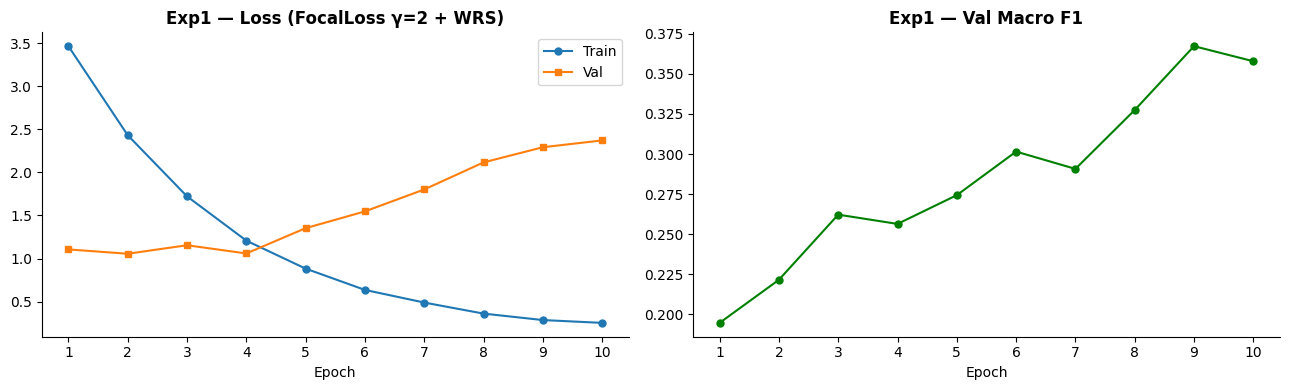

In [18]:
eps1 = range(1, len(exp1_history['train_loss'])+1)
fig, axes = plt.subplots(1,2,figsize=(13,4))
axes[0].plot(eps1, exp1_history['train_loss'], label='Train', marker='o', markersize=5)
axes[0].plot(eps1, exp1_history['val_loss'],   label='Val',   marker='s', markersize=5)
axes[0].set_title('Exp1 — Loss (FocalLoss γ=2 + WRS)', fontweight='bold')
axes[0].set_xlabel('Epoch'); axes[0].legend(); axes[0].spines[['top','right']].set_visible(False)
axes[0].xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
axes[1].plot(eps1, exp1_history['val_f1'], color='green', marker='o', markersize=5)
axes[1].set_title('Exp1 — Val Macro F1', fontweight='bold')
axes[1].set_xlabel('Epoch'); axes[1].spines[['top','right']].set_visible(False)
axes[1].xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
plt.tight_layout()
fig.savefig(EXP1_FIG_DIR/'dinov2_exp1_loss_curve.png', dpi=150, bbox_inches='tight')
plt.show()

Using cache found in /user/HS402/pc01093/.cache/torch/hub/facebookresearch_dinov2_main


Exp1 loaded: epoch=9  val_macro_f1=0.3673


               precision    recall  f1-score   support

        No DR      0.887     0.167     0.280      3872
         Mild      0.088     0.525     0.151       366
     Moderate      0.256     0.698     0.375       794
       Severe      0.424     0.321     0.365       131
Proliferative      0.554     0.528     0.541       106

     accuracy                          0.283      5269
    macro avg      0.442     0.448     0.342      5269
 weighted avg      0.718     0.283     0.293      5269



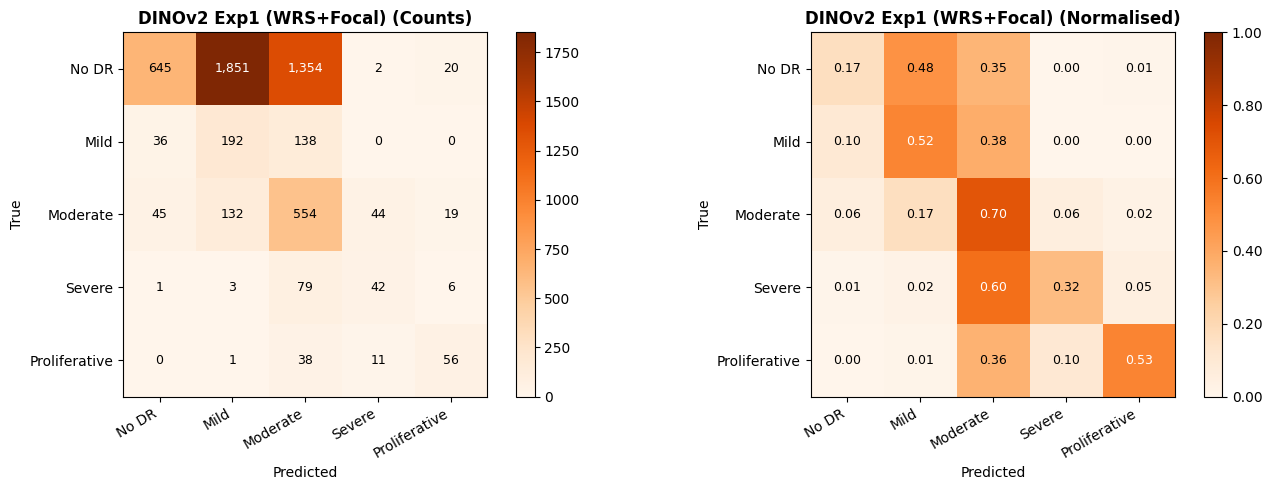

Saved → /scratch/AML Priyanka/AML_G14_CW/outputs/dinov2_exp1/figures/dinov2_exp1_confusion_matrix.png

  Exp1 WRS+FocalLoss
  Macro F1   (PRIMARY) : 0.3425
  QWK                  : 0.3028
  Weighted F1          : 0.2930
  Precision (macro)    : 0.4420
  Recall (macro)       : 0.4476
  mAP                  : 0.4462
  Mean AUC-ROC         : 0.7414
  Top-1 Accuracy       : 0.2826
  ----------------------------------------------------
  Per-class F1:
    No DR               : 0.2805
    Mild                : 0.1509
    Moderate            : 0.3747
    Severe              : 0.3652
    Proliferative       : 0.5411

Exp1 Macro F1 delta vs Baseline: -0.1696
Exp1 QWK delta vs Baseline     : -0.3946


In [19]:
_p_model=globals().get('model',None); _p_crit=globals().get('criterion',None)
model     = DINOv2Classifier().to(device)
criterion = nn.CrossEntropyLoss()
ckpt = torch.load(CKPT_EXP1, map_location=device, weights_only=False)
model.load_state_dict(ckpt['model_state'])
print(f'Exp1 loaded: epoch={ckpt["epoch"]}  val_macro_f1={ckpt["val_macro_f1"]:.4f}')
_, exp1_y_true, exp1_y_pred, exp1_probs = run_epoch(model, test_loader, criterion, None, False)
print(classification_report(exp1_y_true, exp1_y_pred, target_names=CLASS_NAMES, digits=3))
plot_confusion_matrix(exp1_y_true, exp1_y_pred, 'DINOv2 Exp1 (WRS+Focal)',
                      EXP1_FIG_DIR/'dinov2_exp1_confusion_matrix.png', cmap='Oranges')
exp1_metrics = full_metrics(exp1_y_true, exp1_y_pred, exp1_probs, 'Exp1 WRS+FocalLoss')
exp1_qwk=exp1_metrics['qwk']; exp1_acc=exp1_metrics['acc']; exp1_f1_per=exp1_metrics['f1_per']
print(f'\nExp1 Macro F1 delta vs Baseline: {exp1_metrics["macro_f1"]-macro_f1:+.4f}')
print(f'Exp1 QWK delta vs Baseline     : {exp1_qwk-qwk:+.4f}')
if _p_model: model=_p_model; criterion=_p_crit

## 12. Experiment 2 — Enhanced Augmentation
**Hypothesis:** Adding VFlip, Rotation, ColorJitter, and RandomAffine reduces overfitting
and improves minority-class recall — especially for rare grades with few training samples.

| Augmentation | Rationale |
|---|---|
| `RandomVerticalFlip(p=0.5)` | Fundus images have no canonical up/down orientation |
| `RandomRotation(20°)` | Rotation-invariance for vessel and lesion patterns |
| `ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1, hue=0.05)` | Illumination robustness |
| `RandomAffine(translate=0.1, scale=0.9–1.1)` | Camera-position and zoom variance |

> Carried forward from Exp1: `exp1_sampler`, `FocalLoss`, `class_weights_t`.

In [20]:
exp2_train_transform = transforms.Compose([
    transforms.Resize(int(IMAGE_SIZE * 1.05)),
    transforms.RandomCrop(IMAGE_SIZE),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomApply([transforms.RandomRotation(degrees=20)], p=0.5),
    transforms.RandomApply([transforms.ColorJitter(brightness=0.2,contrast=0.2,saturation=0.1,hue=0.05)], p=0.4),
    transforms.RandomApply([transforms.RandomAffine(degrees=0,translate=(0.1,0.1),scale=(0.9,1.1))], p=0.3),
    transforms.ToTensor(),
    transforms.Normalize(DINOV2_MEAN, DINOV2_STD),
])
exp2_train_ds     = DRDataset(train_df, TRAIN_DIR, transform=exp2_train_transform)
exp2_train_loader = DataLoader(exp2_train_ds, batch_size=BATCH_SIZE, sampler=exp1_sampler,
                               num_workers=NUM_WORKERS, pin_memory=True, drop_last=True,
                               persistent_workers=NUM_WORKERS>0)
print(f'Exp2 train loader: {len(exp2_train_loader)} batches  (enhanced augmentation + WRS)')

Exp2 train loader: 3073 batches  (enhanced augmentation + WRS)


In [21]:
set_seed(SEED)
exp2_model     = DINOv2Classifier().to(device)
exp2_criterion = FocalLoss(alpha=class_weights_t, gamma=2.0)
exp2_optimizer = torch.optim.AdamW(exp2_model.param_groups(LR_BACKBONE, LR_HEAD, WEIGHT_DECAY))
exp2_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(exp2_optimizer, T_max=EPOCHS)
exp2_scaler    = torch.amp.GradScaler('cuda', enabled=use_amp)

EXP2_OUT_DIR  = ROOT/'outputs'/'dinov2_exp2'; EXP2_CKPT_DIR=EXP2_OUT_DIR/'checkpoints'; EXP2_FIG_DIR=EXP2_OUT_DIR/'figures'
for d in (EXP2_CKPT_DIR,EXP2_FIG_DIR): d.mkdir(parents=True,exist_ok=True)
EXP2_BEST_PATH = EXP2_CKPT_DIR/'dinov2_exp2_best.pt'

_b2m=globals().get('model',None); _b2c=globals().get('criterion',None)
_b2o=globals().get('optimizer',None); _b2s=globals().get('scaler',None)
model,criterion,optimizer,scaler = exp2_model,exp2_criterion,exp2_optimizer,exp2_scaler

exp2_best_f1=0.0; exp2_pat=EARLY_STOPPING_PATIENCE
exp2_history={'train_loss':[],'val_loss':[],'train_acc':[],'val_acc':[],'val_f1':[]}
print(f"{'Epoch':<8} {'Tr Loss':>10} {'Tr Acc':>8} {'Val Loss':>10} {'Val Acc':>8} {'Val F1':>8}")
print('─'*60)
for epoch in range(1, EPOCHS+1):
    torch.cuda.empty_cache()
    tl,tlab,tprd,_ = run_epoch(model,exp2_train_loader,criterion,optimizer,True,scaler)
    vl,vlab,vprd,_ = run_epoch(model,val_loader,criterion,None,False)
    exp2_scheduler.step()
    ta=accuracy_score(tlab,tprd); va=accuracy_score(vlab,vprd)
    vf=f1_score(vlab,vprd,average='macro',zero_division=0)
    exp2_history['train_loss'].append(tl); exp2_history['val_loss'].append(vl)
    exp2_history['train_acc'].append(ta);  exp2_history['val_acc'].append(va); exp2_history['val_f1'].append(vf)
    mk=''
    if vf>exp2_best_f1+1e-4:
        exp2_best_f1=vf; exp2_pat=EARLY_STOPPING_PATIENCE
        torch.save({'epoch':epoch,'model_state':model.state_dict(),'val_macro_f1':vf,'val_loss':vl},EXP2_BEST_PATH); mk='  ← best'
    else:
        exp2_pat-=1
    print(f'{epoch:<8} {tl:>10.4f} {ta:>8.4f} {vl:>10.4f} {va:>8.4f} {vf:>8.4f}{mk}')
    if exp2_pat==0: print(f'Early stopping @ ep {epoch}.'); break
print(f'\nBest Val Macro F1: {exp2_best_f1:.4f}')
if _b2m: model=_b2m; criterion=_b2c; optimizer=_b2o; scaler=_b2s

Using cache found in /user/HS402/pc01093/.cache/torch/hub/facebookresearch_dinov2_main


Epoch       Tr Loss   Tr Acc   Val Loss  Val Acc   Val F1
────────────────────────────────────────────────────────────


1            3.6803   0.4322     1.0810   0.0922   0.1379  ← best


2            2.8697   0.4947     0.9454   0.1031   0.1706  ← best


3            2.3142   0.5352     1.1903   0.0991   0.1468


...

6            0.9934   0.6411     1.4286   0.1374   0.2809


7            0.6916   0.6691     1.5986   0.1465   0.2802


8            0.5010   0.6962     1.6590   0.1640   0.3077  ← best


9            0.4009   0.7201     1.8794   0.1695   0.3199  ← best


10           0.3612   0.7310     1.9123   0.1704   0.3162

Best Val Macro F1: 0.3199


Using cache found in /user/HS402/pc01093/.cache/torch/hub/facebookresearch_dinov2_main


Exp2 loaded: epoch=9  val_macro_f1=0.3199


               precision    recall  f1-score   support

        No DR      0.847     0.013     0.025      3872
         Mild      0.076     0.740     0.138       366
     Moderate      0.318     0.555     0.405       794
       Severe      0.385     0.435     0.409       131
Proliferative      0.554     0.585     0.569       106

     accuracy                          0.167      5269
    macro avg      0.436     0.466     0.309      5269
 weighted avg      0.697     0.167     0.111      5269



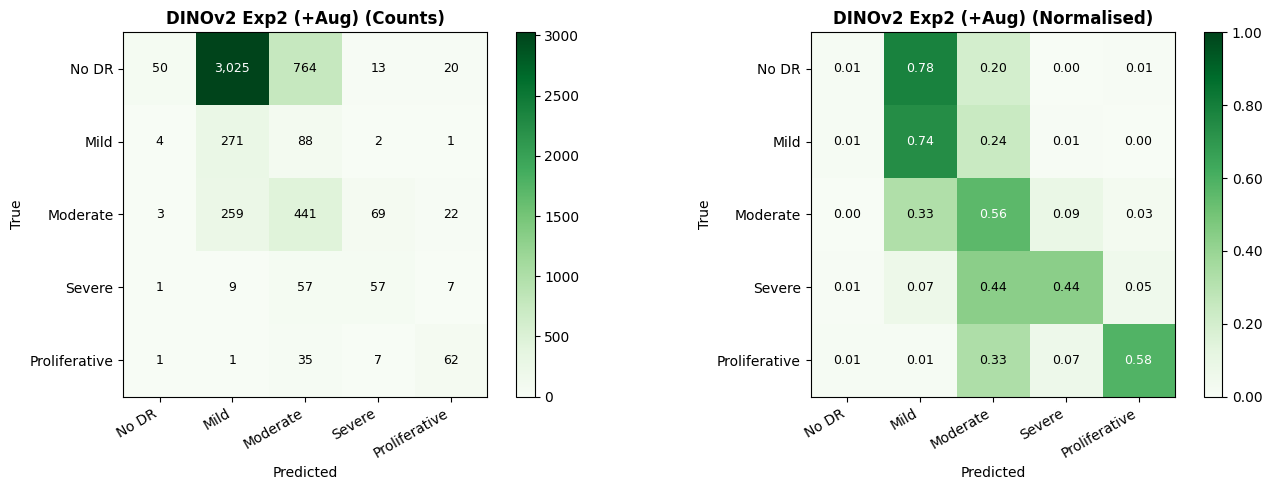

Saved → /scratch/AML Priyanka/AML_G14_CW/outputs/dinov2_exp2/figures/dinov2_exp2_confusion_matrix.png

  Exp2 +Augmentation
  Macro F1   (PRIMARY) : 0.3091
  QWK                  : 0.3358
  Weighted F1          : 0.1109
  Precision (macro)    : 0.4361
  Recall (macro)       : 0.4658
  mAP                  : 0.4440
  Mean AUC-ROC         : 0.7468
  Top-1 Accuracy       : 0.1672
  ----------------------------------------------------
  Per-class F1:
    No DR               : 0.0254
    Mild                : 0.1379
    Moderate            : 0.4048
    Severe              : 0.4086
    Proliferative       : 0.5688
Exp2 Macro F1 delta vs Baseline: -0.2030


In [22]:
_p2m=globals().get('model',None); _p2c=globals().get('criterion',None)
model=DINOv2Classifier().to(device); criterion=nn.CrossEntropyLoss()
ckpt=torch.load(CKPT_EXP2,map_location=device,weights_only=False)
model.load_state_dict(ckpt['model_state'])
print(f'Exp2 loaded: epoch={ckpt["epoch"]}  val_macro_f1={ckpt["val_macro_f1"]:.4f}')
_,exp2_y_true,exp2_y_pred,exp2_probs=run_epoch(model,test_loader,criterion,None,False)
print(classification_report(exp2_y_true,exp2_y_pred,target_names=CLASS_NAMES,digits=3))
plot_confusion_matrix(exp2_y_true,exp2_y_pred,'DINOv2 Exp2 (+Aug)',EXP2_FIG_DIR/'dinov2_exp2_confusion_matrix.png',cmap='Greens')
exp2_metrics=full_metrics(exp2_y_true,exp2_y_pred,exp2_probs,'Exp2 +Augmentation')
exp2_qwk=exp2_metrics['qwk']; exp2_acc=exp2_metrics['acc']; exp2_f1_per=exp2_metrics['f1_per']
print(f'Exp2 Macro F1 delta vs Baseline: {exp2_metrics["macro_f1"]-macro_f1:+.4f}')
if _p2m: model=_p2m; criterion=_p2c

## 13. Experiment 3 — Two-Phase Freeze→Unfreeze Fine-tuning
**Hypothesis:** Training all layers from epoch 1 risks distorting DINOv2's powerful
self-supervised features before the head stabilises. A two-phase strategy:
- **Phase 1 (5 epochs):** Freeze backbone, train head only at high LR → head adapts to DR task
- **Phase 2 (remaining):** Unfreeze all blocks, fine-tune end-to-end at lower LR → refinement

> Carries forward Exp1+2 best config: WRS + FocalLoss + enhanced augmentation.

In [23]:
set_seed(SEED)
PHASE1_EPOCHS = 5

EXP3_OUT_DIR  = ROOT/'outputs'/'dinov2_exp3'; EXP3_CKPT_DIR=EXP3_OUT_DIR/'checkpoints'; EXP3_FIG_DIR=EXP3_OUT_DIR/'figures'
for d in (EXP3_CKPT_DIR,EXP3_FIG_DIR): d.mkdir(parents=True,exist_ok=True)
EXP3_P1_PATH = EXP3_CKPT_DIR/'dinov2_exp3_phase1_best.pt'
EXP3_BEST_PATH = EXP3_CKPT_DIR/'dinov2_exp3_best.pt'

# Phase 1 — head only
exp3_model = DINOv2Classifier(freeze_backbone=True).to(device)   # backbone frozen
exp3_opt_p1 = torch.optim.AdamW(
    [p for p in exp3_model.parameters() if p.requires_grad],
    lr=LR_HEAD*5, weight_decay=WEIGHT_DECAY   # higher LR for head-only phase
)
exp3_sch_p1 = torch.optim.lr_scheduler.CosineAnnealingLR(exp3_opt_p1, T_max=PHASE1_EPOCHS)
exp3_scaler = torch.amp.GradScaler('cuda', enabled=use_amp)
exp3_crit   = FocalLoss(alpha=class_weights_t, gamma=2.0)

_b3m=globals().get('model',None); _b3c=globals().get('criterion',None)
_b3o=globals().get('optimizer',None); _b3s=globals().get('scaler',None)
model,criterion,optimizer,scaler = exp3_model,exp3_crit,exp3_opt_p1,exp3_scaler

exp3_best_p1_f1=0.0; exp3_history={'train_loss':[],'val_loss':[],'val_f1':[],'phase':[]}
print('── Phase 1: Head-only training ──────────────────────────────')
trainable_p1 = sum(p.numel() for p in exp3_model.parameters() if p.requires_grad)
print(f'Trainable params: {trainable_p1:,}')
print(f"{'Epoch':<8} {'Tr Loss':>10} {'Val Loss':>10} {'Val F1':>8}")
print('─'*45)

for epoch in range(1, PHASE1_EPOCHS+1):
    torch.cuda.empty_cache()
    tl,tlab,tprd,_=run_epoch(model,exp2_train_loader,criterion,optimizer,True,scaler)
    vl,vlab,vprd,_=run_epoch(model,val_loader,criterion,None,False)
    exp3_sch_p1.step()
    vf=f1_score(vlab,vprd,average='macro',zero_division=0)
    exp3_history['train_loss'].append(tl); exp3_history['val_loss'].append(vl)
    exp3_history['val_f1'].append(vf); exp3_history['phase'].append(1)
    mk=''
    if vf>exp3_best_p1_f1+1e-4:
        exp3_best_p1_f1=vf
        torch.save({'epoch':epoch,'model_state':model.state_dict(),'val_macro_f1':vf,'val_loss':vl},EXP3_P1_PATH); mk='  ← best'
    print(f'{epoch:<8} {tl:>10.4f} {vl:>10.4f} {vf:>8.4f}{mk}')

# Phase 2 — unfreeze all blocks
print('\n── Phase 2: Full fine-tuning ────────────────────────────────')
for p in exp3_model.backbone.parameters(): p.requires_grad = True
exp3_opt_p2 = torch.optim.AdamW(exp3_model.param_groups(LR_BACKBONE, LR_HEAD, WEIGHT_DECAY))
exp3_sch_p2 = torch.optim.lr_scheduler.CosineAnnealingLR(exp3_opt_p2, T_max=EPOCHS)
optimizer = exp3_opt_p2
trainable_p2 = sum(p.numel() for p in exp3_model.parameters() if p.requires_grad)
print(f'Trainable params: {trainable_p2:,}')
print(f"{'Epoch':<8} {'Tr Loss':>10} {'Val Loss':>10} {'Val F1':>8}")
print('─'*45)

exp3_best_f1=0.0; exp3_pat=EARLY_STOPPING_PATIENCE
for epoch in range(1, EPOCHS+1):
    torch.cuda.empty_cache()
    tl,tlab,tprd,_=run_epoch(model,exp2_train_loader,criterion,optimizer,True,scaler)
    vl,vlab,vprd,_=run_epoch(model,val_loader,criterion,None,False)
    exp3_sch_p2.step()
    vf=f1_score(vlab,vprd,average='macro',zero_division=0)
    exp3_history['train_loss'].append(tl); exp3_history['val_loss'].append(vl)
    exp3_history['val_f1'].append(vf); exp3_history['phase'].append(2)
    mk=''
    if vf>exp3_best_f1+1e-4:
        exp3_best_f1=vf; exp3_pat=EARLY_STOPPING_PATIENCE
        torch.save({'epoch':PHASE1_EPOCHS+epoch,'model_state':model.state_dict(),'val_macro_f1':vf,'val_loss':vl},EXP3_BEST_PATH); mk='  ← best'
    else:
        exp3_pat-=1
    print(f'{PHASE1_EPOCHS+epoch:<8} {tl:>10.4f} {vl:>10.4f} {vf:>8.4f}{mk}')
    if exp3_pat==0: print(f'Early stopping @ ep {PHASE1_EPOCHS+epoch}.'); break
print(f'\nBest Val Macro F1 (Phase 2): {exp3_best_f1:.4f}')
if _b3m: model=_b3m; criterion=_b3c; optimizer=_b3o; scaler=_b3s

Using cache found in /user/HS402/pc01093/.cache/torch/hub/facebookresearch_dinov2_main


── Phase 1: Head-only training ──────────────────────────────
Trainable params: 396,293
Epoch       Tr Loss   Val Loss   Val F1
─────────────────────────────────────────────


1            3.9543     1.0831   0.1173  ← best


2            3.4416     1.0690   0.1087


3            3.1041     1.1617   0.1171


...

11           0.8247     1.6306   0.2828  ← best


12           0.5898     1.6899   0.3004  ← best


13           0.4467     1.9548   0.3066  ← best


14           0.3725     2.2330   0.3077  ← best


15           0.3126     2.3926   0.3132  ← best

Best Val Macro F1 (Phase 2): 0.3132


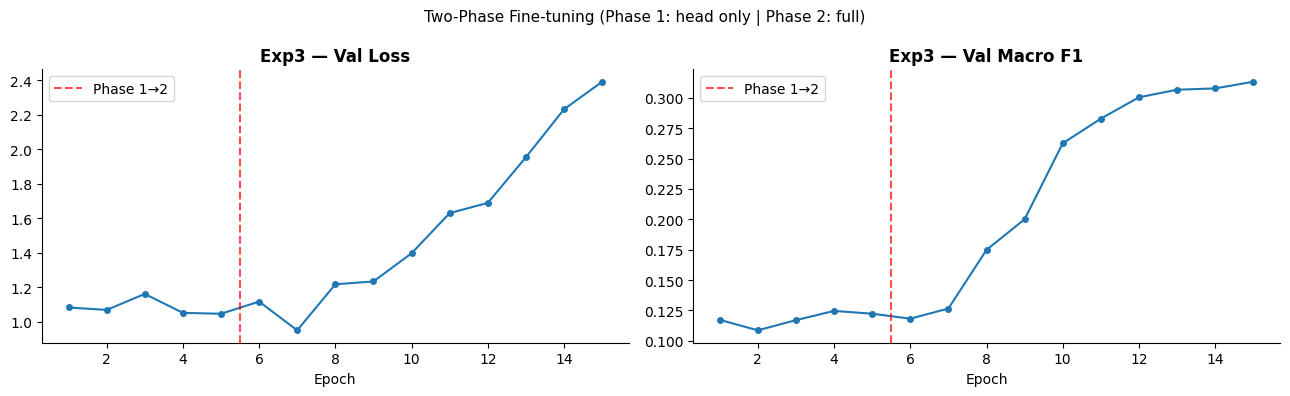

In [24]:
eps3 = range(1, len(exp3_history['train_loss'])+1)
phase_boundary = PHASE1_EPOCHS + 0.5
fig, axes = plt.subplots(1,2,figsize=(13,4))
for ax, key, title in [
    (axes[0],'val_loss','Val Loss'),
    (axes[1],'val_f1', 'Val Macro F1')
]:
    ax.plot(eps3, exp3_history[key], marker='o', markersize=4)
    ax.axvline(x=phase_boundary, color='red', linestyle='--', alpha=0.7, label='Phase 1→2')
    ax.set_title(f'Exp3 — {title}', fontweight='bold'); ax.set_xlabel('Epoch')
    ax.legend(); ax.spines[['top','right']].set_visible(False)
    ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
plt.suptitle('Two-Phase Fine-tuning (Phase 1: head only | Phase 2: full)', fontsize=11)
plt.tight_layout()
fig.savefig(EXP3_FIG_DIR/'dinov2_exp3_curves.png', dpi=150, bbox_inches='tight')
plt.show()

Using cache found in /user/HS402/pc01093/.cache/torch/hub/facebookresearch_dinov2_main


Exp3 loaded: epoch=15  val_macro_f1=0.3132


               precision    recall  f1-score   support

        No DR      0.910     0.026     0.051      3872
         Mild      0.076     0.612     0.136       366
     Moderate      0.257     0.640     0.367       794
       Severe      0.384     0.427     0.404       131
Proliferative      0.621     0.604     0.612       106

     accuracy                          0.181      5269
    macro avg      0.450     0.462     0.314      5269
 weighted avg      0.735     0.181     0.124      5269



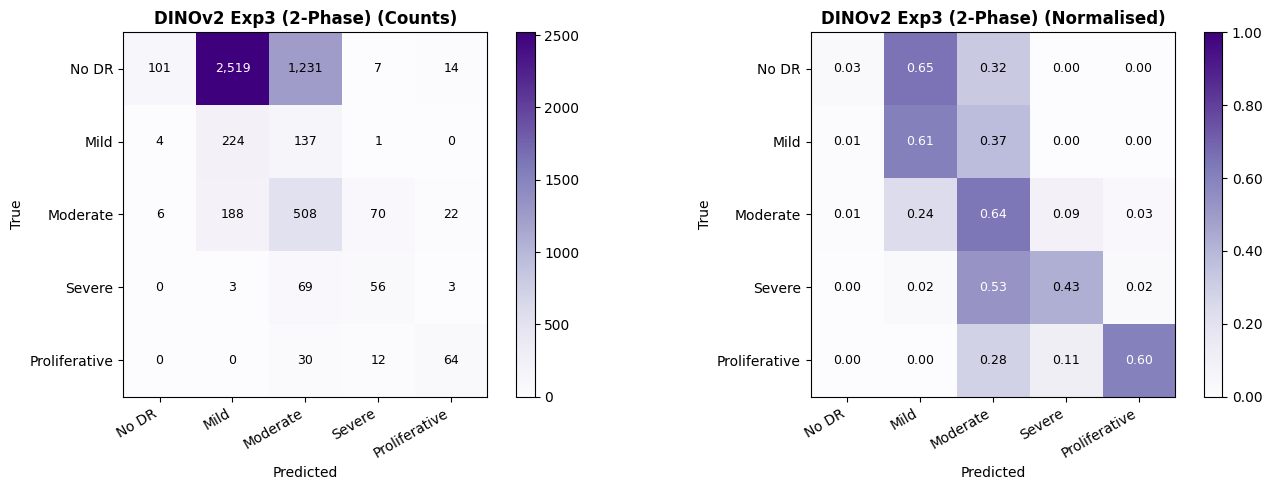

Saved → /scratch/AML Priyanka/AML_G14_CW/outputs/dinov2_exp3/figures/dinov2_exp3_confusion_matrix.png

  Exp3 Two-Phase
  Macro F1   (PRIMARY) : 0.3140
  QWK                  : 0.2995
  Weighted F1          : 0.1244
  Precision (macro)    : 0.4497
  Recall (macro)       : 0.4618
  mAP                  : 0.4637
  Mean AUC-ROC         : 0.7546
  Top-1 Accuracy       : 0.1809
  ----------------------------------------------------
  Per-class F1:
    No DR               : 0.0507
    Mild                : 0.1358
    Moderate            : 0.3669
    Severe              : 0.4043
    Proliferative       : 0.6124
Exp3 Macro F1 delta vs Baseline: -0.1981


In [25]:
_p3m=globals().get('model',None); _p3c=globals().get('criterion',None)
model=DINOv2Classifier().to(device); criterion=nn.CrossEntropyLoss()
ckpt=torch.load(CKPT_EXP3,map_location=device,weights_only=False)
model.load_state_dict(ckpt['model_state'])
print(f'Exp3 loaded: epoch={ckpt["epoch"]}  val_macro_f1={ckpt["val_macro_f1"]:.4f}')
_,exp3_y_true,exp3_y_pred,exp3_probs=run_epoch(model,test_loader,criterion,None,False)
print(classification_report(exp3_y_true,exp3_y_pred,target_names=CLASS_NAMES,digits=3))
plot_confusion_matrix(exp3_y_true,exp3_y_pred,'DINOv2 Exp3 (2-Phase)',EXP3_FIG_DIR/'dinov2_exp3_confusion_matrix.png',cmap='Purples')
exp3_metrics=full_metrics(exp3_y_true,exp3_y_pred,exp3_probs,'Exp3 Two-Phase')
exp3_qwk=exp3_metrics['qwk']; exp3_acc=exp3_metrics['acc']; exp3_f1_per=exp3_metrics['f1_per']
print(f'Exp3 Macro F1 delta vs Baseline: {exp3_metrics["macro_f1"]-macro_f1:+.4f}')
if _p3m: model=_p3m; criterion=_p3c

## 14. Experiment 4 — Majority-Class Downsampling
**Hypothesis:** Grade 0 (No DR) = ~73.5% of training data, overwhelming the model.
Capping Grade 0 to Grade 2's count removes excess negatives at the **data level**,
without relying on loss-level reweighting.

**Design:** Plain `CrossEntropyLoss`, no sampler — isolates the effect of data-level rebalancing.

| Class | Original | Exp4 |
|---|---|---|
| Grade 0 No DR | ~18,000 | capped to Grade 2 count |
| Grade 1–4 | unchanged | unchanged |

> **Comparison vs Exp1:** Exp1 keeps all data but reweights via WRS+FocalLoss.
> Exp4 removes excess at source and uses plain CE — isolating pre-training vs in-training strategies.

In [26]:
grade2_count   = (train_df['level']==2).sum()
grade0_capped  = train_df[train_df['level']==0].sample(n=grade2_count, random_state=SEED)
exp4_train_df  = (pd.concat([grade0_capped, train_df[train_df['level']!=0]])
                  .sample(frac=1, random_state=SEED).reset_index(drop=True))

print(f'Original: {len(train_df):,}  Exp4: {len(exp4_train_df):,}  (Grade 0 capped to {grade2_count:,})')
print(f'\n{"Grade":<6} {"Name":<18} {"Original":>10} {"Exp4":>8}')
print('-'*46)
for g, name in enumerate(CLASS_NAMES):
    orig = (train_df['level']==g).sum()
    new  = (exp4_train_df['level']==g).sum()
    note = '  ← capped' if g==0 else ''
    print(f'  {g}    {name:<18} {orig:>9,}  {new:>7,}{note}')

exp4_train_ds = DRDataset(exp4_train_df, TRAIN_DIR, transform=exp2_train_transform)
exp4_train_loader = DataLoader(exp4_train_ds, batch_size=BATCH_SIZE, shuffle=True,
                               num_workers=NUM_WORKERS, pin_memory=True, drop_last=True,
                               persistent_workers=NUM_WORKERS>0)
print(f'\nExp4 train loader: {len(exp4_train_loader)} batches/epoch')

Original: 24,588  Exp4: 10,225  (Grade 0 capped to 3,704)

Grade  Name                 Original     Exp4
----------------------------------------------
  0    No DR                 18,067    3,704  ← capped
  1    Mild                   1,710    1,710
  2    Moderate               3,704    3,704
  3    Severe                   611      611
  4    Proliferative            496      496

Exp4 train loader: 1278 batches/epoch


In [27]:
set_seed(SEED)
exp4_model     = DINOv2Classifier().to(device)
exp4_criterion = nn.CrossEntropyLoss()   # plain CE — no class weights
exp4_optimizer = torch.optim.AdamW(exp4_model.param_groups(LR_BACKBONE, LR_HEAD, WEIGHT_DECAY))
exp4_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(exp4_optimizer, T_max=EPOCHS)
exp4_scaler    = torch.amp.GradScaler('cuda', enabled=use_amp)

EXP4_OUT_DIR=ROOT/'outputs'/'dinov2_exp4'; EXP4_CKPT_DIR=EXP4_OUT_DIR/'checkpoints'; EXP4_FIG_DIR=EXP4_OUT_DIR/'figures'
for d in (EXP4_CKPT_DIR,EXP4_FIG_DIR): d.mkdir(parents=True,exist_ok=True)
EXP4_BEST_PATH = EXP4_CKPT_DIR/'dinov2_exp4_best.pt'

_b4m=globals().get('model',None); _b4c=globals().get('criterion',None)
_b4o=globals().get('optimizer',None); _b4s=globals().get('scaler',None)
model,criterion,optimizer,scaler=exp4_model,exp4_criterion,exp4_optimizer,exp4_scaler

exp4_best_f1=0.0; exp4_pat=EARLY_STOPPING_PATIENCE
exp4_history={'train_loss':[],'val_loss':[],'val_f1':[]}
print(f"{'Epoch':<8} {'Tr Loss':>10} {'Val Loss':>10} {'Val F1':>8}")
print('─'*45)
for epoch in range(1, EPOCHS+1):
    torch.cuda.empty_cache()
    tl,tlab,tprd,_=run_epoch(model,exp4_train_loader,criterion,optimizer,True,scaler)
    vl,vlab,vprd,_=run_epoch(model,val_loader,criterion,None,False)
    exp4_scheduler.step()
    vf=f1_score(vlab,vprd,average='macro',zero_division=0)
    exp4_history['train_loss'].append(tl); exp4_history['val_loss'].append(vl); exp4_history['val_f1'].append(vf)
    mk=''
    if vf>exp4_best_f1+1e-4:
        exp4_best_f1=vf; exp4_pat=EARLY_STOPPING_PATIENCE
        torch.save({'epoch':epoch,'model_state':model.state_dict(),'val_macro_f1':vf,'val_loss':vl},EXP4_BEST_PATH); mk='  ← best'
    else:
        exp4_pat-=1
    print(f'{epoch:<8} {tl:>10.4f} {vl:>10.4f} {vf:>8.4f}{mk}')
    if exp4_pat==0: print(f'Early stopping @ ep {epoch}.'); break
print(f'\nBest Val Macro F1: {exp4_best_f1:.4f}')
if _b4m: model=_b4m; criterion=_b4c; optimizer=_b4o; scaler=_b4s

Using cache found in /user/HS402/pc01093/.cache/torch/hub/facebookresearch_dinov2_main


Epoch       Tr Loss   Val Loss   Val F1
─────────────────────────────────────────────


1            1.3029     0.8526   0.3419  ← best


2            1.1228     0.9757   0.4318  ← best


3            1.0969     0.8164   0.3968


...

6            0.9827     0.9085   0.4985  ← best


7            0.9477     0.7667   0.4752


8            0.9169     0.7653   0.5213  ← best


9            0.8857     0.8427   0.5164


10           0.8624     0.7675   0.5215  ← best

Best Val Macro F1: 0.5215


Using cache found in /user/HS402/pc01093/.cache/torch/hub/facebookresearch_dinov2_main


Exp4 loaded: epoch=10  val_macro_f1=0.5215


               precision    recall  f1-score   support

        No DR      0.875     0.868     0.872      3872
         Mild      0.176     0.068     0.098       366
     Moderate      0.464     0.640     0.538       794
       Severe      0.512     0.336     0.406       131
Proliferative      0.638     0.632     0.635       106

     accuracy                          0.760      5269
    macro avg      0.533     0.509     0.510      5269
 weighted avg      0.751     0.760     0.751      5269



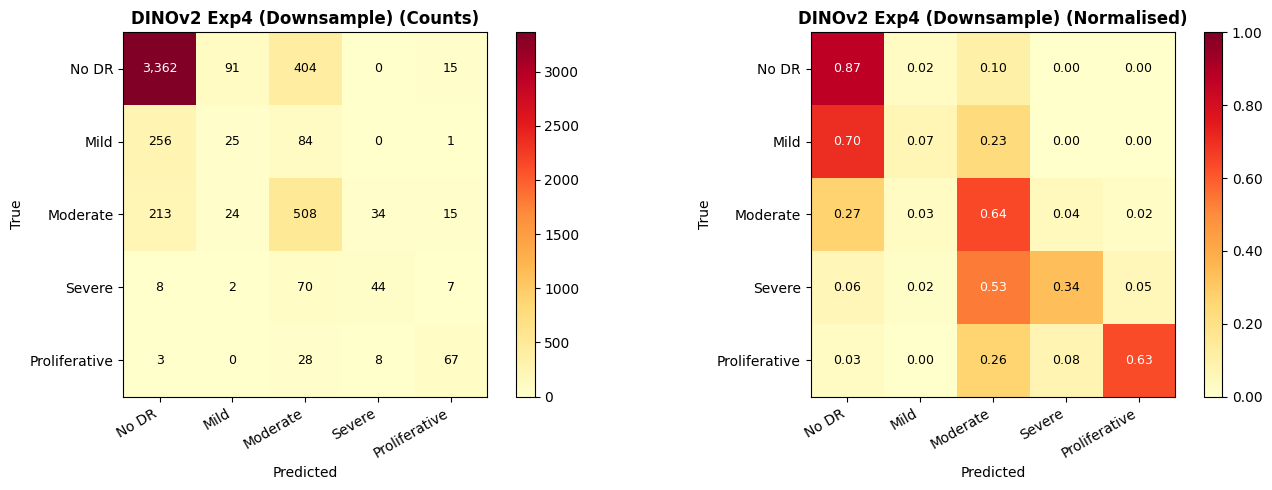

Saved → /scratch/AML Priyanka/AML_G14_CW/outputs/dinov2_exp4/figures/dinov2_exp4_confusion_matrix.png

  Exp4 Downsampling
  Macro F1   (PRIMARY) : 0.5098
  QWK                  : 0.6488
  Weighted F1          : 0.7513
  Precision (macro)    : 0.5330
  Recall (macro)       : 0.5089
  mAP                  : 0.5392
  Mean AUC-ROC         : 0.8478
  Top-1 Accuracy       : 0.7603
  ----------------------------------------------------
  Per-class F1:
    No DR               : 0.8717
    Mild                : 0.0984
    Moderate            : 0.5381
    Severe              : 0.4055
    Proliferative       : 0.6351
Exp4 Macro F1 delta vs Baseline: -0.0023


In [28]:
_p4m=globals().get('model',None); _p4c=globals().get('criterion',None)
model=DINOv2Classifier().to(device); criterion=nn.CrossEntropyLoss()
ckpt=torch.load(CKPT_EXP4,map_location=device,weights_only=False)
model.load_state_dict(ckpt['model_state'])
print(f'Exp4 loaded: epoch={ckpt["epoch"]}  val_macro_f1={ckpt["val_macro_f1"]:.4f}')
_,exp4_y_true,exp4_y_pred,exp4_probs=run_epoch(model,test_loader,criterion,None,False)
print(classification_report(exp4_y_true,exp4_y_pred,target_names=CLASS_NAMES,digits=3))
plot_confusion_matrix(exp4_y_true,exp4_y_pred,'DINOv2 Exp4 (Downsample)',EXP4_FIG_DIR/'dinov2_exp4_confusion_matrix.png',cmap='YlOrRd')
exp4_metrics=full_metrics(exp4_y_true,exp4_y_pred,exp4_probs,'Exp4 Downsampling')
exp4_qwk=exp4_metrics['qwk']; exp4_acc=exp4_metrics['acc']; exp4_f1_per=exp4_metrics['f1_per']
print(f'Exp4 Macro F1 delta vs Baseline: {exp4_metrics["macro_f1"]-macro_f1:+.4f}')
if _p4m: model=_p4m; criterion=_p4c

## 15. Experiment 5 — DINOv2 Fine-Tuning Depth + Attention Maps
**Unique to DINOv2** — explores how many of the 12 ViT-B/14 transformer blocks to unfreeze.
Also visualises self-attention maps showing what retinal regions the model focuses on.

| Run | Blocks unfrozen | ~Trainable params |
|---|---|---|
| E5-A | Head only | ~1M |
| E5-B | Last 3 blocks + head | ~30M |
| E5-C | Last 6 blocks + head | ~57M |
| E5-D | All 12 blocks + head | ~86M |


───────────────────────────────────────────────────────
  E5-headonly
───────────────────────────────────────────────────────


Using cache found in /user/HS402/pc01093/.cache/torch/hub/facebookresearch_dinov2_main


  Trainable: 396,293
Epoch      Val F1


1          0.1210  ← best


2          0.1279  ← best


...

7          0.1309


8          0.1501  ← best


9          0.1355


10         0.1505  ← best



  E5-headonly
  Macro F1   (PRIMARY) : 0.1535
  QWK                  : 0.3037
  Weighted F1          : 0.0366
  Precision (macro)    : 0.1269
  Recall (macro)       : 0.4661
  mAP                  : 0.3564
  Mean AUC-ROC         : 0.7258
  Top-1 Accuracy       : 0.1008
  ----------------------------------------------------
  Per-class F1:
    No DR               : 0.0000
    Mild                : 0.1445
    Moderate            : 0.0991
    Severe              : 0.2300
    Proliferative       : 0.2941


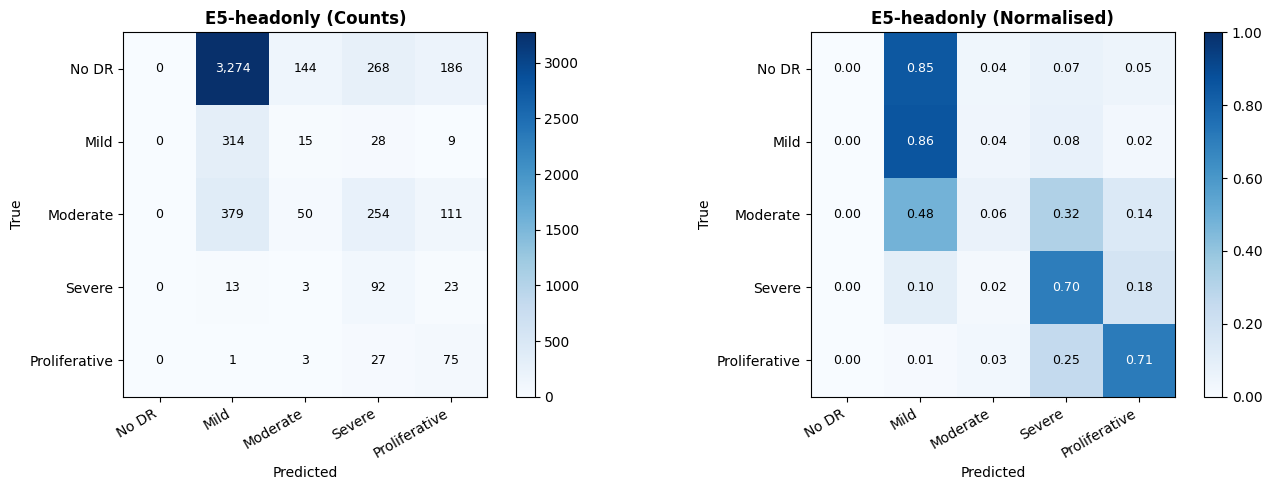

Saved → /scratch/AML Priyanka/AML_G14_CW/outputs/dinov2_exp5/figures/dinov2_exp5_headonly_cm.png
Best Val Macro F1: 0.1505

───────────────────────────────────────────────────────
  E5-last3
───────────────────────────────────────────────────────


Using cache found in /user/HS402/pc01093/.cache/torch/hub/facebookresearch_dinov2_main


  Trainable: 21,666,053
Epoch      Val F1


1          0.1654  ← best


2          0.2536  ← best


...

7          0.2970  ← best


8          0.3094  ← best


9          0.3154  ← best


10         0.3120



  E5-last3
  Macro F1   (PRIMARY) : 0.3215
  QWK                  : 0.3269
  Weighted F1          : 0.1097
  Precision (macro)    : 0.4458
  Recall (macro)       : 0.4796
  mAP                  : 0.4549
  Mean AUC-ROC         : 0.7455
  Top-1 Accuracy       : 0.1737
  ----------------------------------------------------
  Per-class F1:
    No DR               : 0.0209
    Mild                : 0.1411
    Moderate            : 0.4098
    Severe              : 0.4103
    Proliferative       : 0.6256


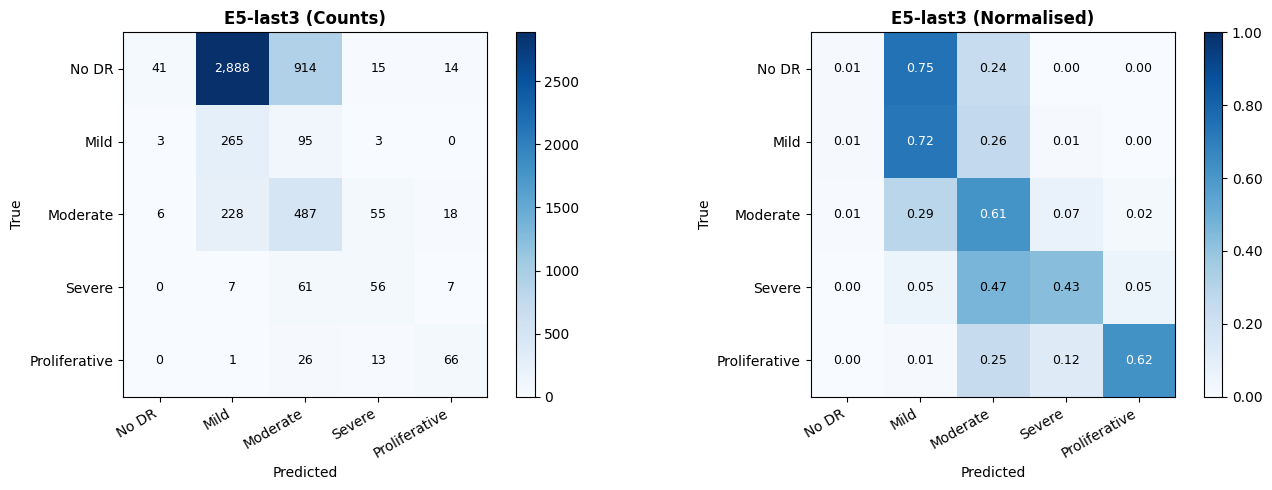

Saved → /scratch/AML Priyanka/AML_G14_CW/outputs/dinov2_exp5/figures/dinov2_exp5_last3_cm.png
Best Val Macro F1: 0.3154

───────────────────────────────────────────────────────
  E5-last6
───────────────────────────────────────────────────────


Using cache found in /user/HS402/pc01093/.cache/torch/hub/facebookresearch_dinov2_main


  Trainable: 42,934,277
Epoch      Val F1


1          0.1440  ← best


2          0.2298  ← best


...

7          0.3012


8          0.3378  ← best


9          0.3247


10         0.3311



  E5-last6
  Macro F1   (PRIMARY) : 0.3311
  QWK                  : 0.3432
  Weighted F1          : 0.1409
  Precision (macro)    : 0.4587
  Recall (macro)       : 0.4885
  mAP                  : 0.4601
  Mean AUC-ROC         : 0.7649
  Top-1 Accuracy       : 0.1888
  ----------------------------------------------------
  Per-class F1:
    No DR               : 0.0628
    Mild                : 0.1446
    Moderate            : 0.4105
    Severe              : 0.4191
    Proliferative       : 0.6182


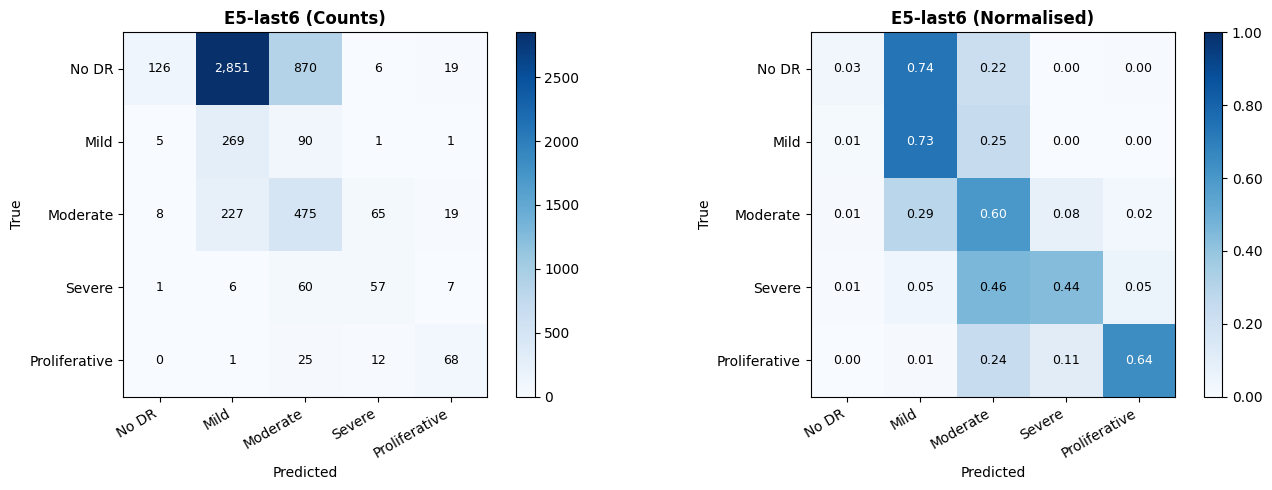

Saved → /scratch/AML Priyanka/AML_G14_CW/outputs/dinov2_exp5/figures/dinov2_exp5_last6_cm.png
Best Val Macro F1: 0.3378

───────────────────────────────────────────────────────
  E5-allblocks
───────────────────────────────────────────────────────


Using cache found in /user/HS402/pc01093/.cache/torch/hub/facebookresearch_dinov2_main


  Trainable: 86,976,773
Epoch      Val F1


1          0.1432  ← best


2          0.1503  ← best


...

7          0.2442  ← best


8          0.2703  ← best


9          0.2816  ← best


10         0.2890  ← best



  E5-allblocks
  Macro F1   (PRIMARY) : 0.2903
  QWK                  : 0.3805
  Weighted F1          : 0.0887
  Precision (macro)    : 0.2424
  Recall (macro)       : 0.4848
  mAP                  : 0.4390
  Mean AUC-ROC         : 0.7460
  Top-1 Accuracy       : 0.1461
  ----------------------------------------------------
  Per-class F1:
    No DR               : 0.0000
    Mild                : 0.1409
    Moderate            : 0.3892
    Severe              : 0.3702
    Proliferative       : 0.5512


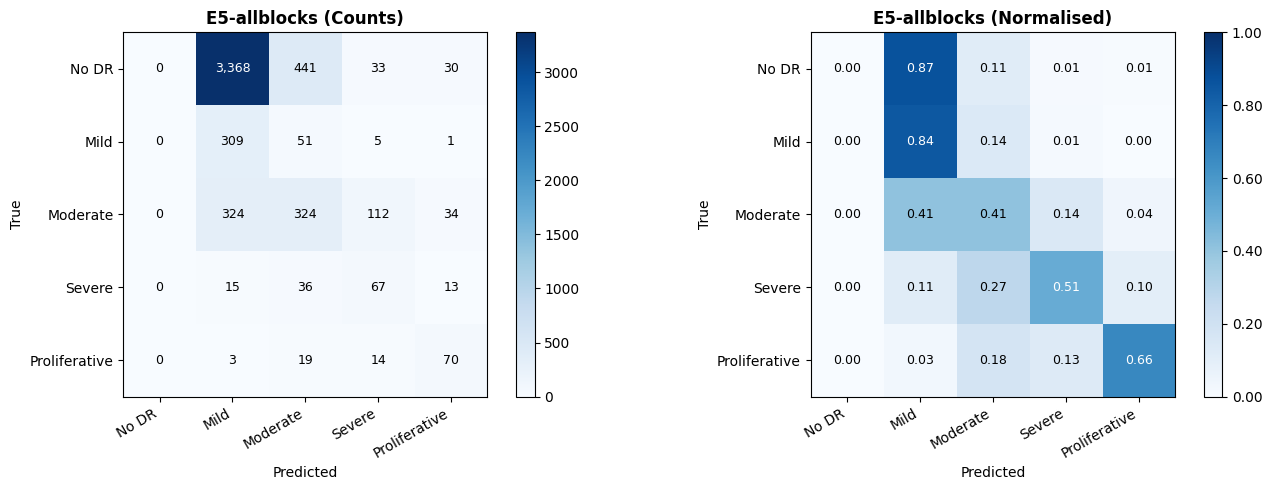

Saved → /scratch/AML Priyanka/AML_G14_CW/outputs/dinov2_exp5/figures/dinov2_exp5_allblocks_cm.png
Best Val Macro F1: 0.2890


In [29]:
exp5_configs = [
    {'tag':'headonly',   'freeze':True,  'blocks': 0, 'ckpt':CKPT_EXP5_A},
    {'tag':'last3',      'freeze':False, 'blocks': 3, 'ckpt':CKPT_EXP5_B},
    {'tag':'last6',      'freeze':False, 'blocks': 6, 'ckpt':CKPT_EXP5_C},
    {'tag':'allblocks',  'freeze':False, 'blocks':-1, 'ckpt':CKPT_EXP5_D},
]
EXP5_OUT_DIR=ROOT/'outputs'/'dinov2_exp5'; EXP5_CKPT_DIR=EXP5_OUT_DIR/'checkpoints'; EXP5_FIG_DIR=EXP5_OUT_DIR/'figures'
for d in (EXP5_CKPT_DIR,EXP5_FIG_DIR): d.mkdir(parents=True,exist_ok=True)

exp5_results = {}
exp5_models  = {}   # keep for attention maps

for cfg in exp5_configs:
    print(f'\n{"─"*55}\n  E5-{cfg["tag"]}\n{"─"*55}')
    set_seed(SEED)
    m = DINOv2Classifier(freeze_backbone=cfg['freeze'], unfreeze_blocks=cfg['blocks']).to(device)
    tp = sum(p.numel() for p in m.parameters() if p.requires_grad)
    print(f'  Trainable: {tp:,}')
    op = torch.optim.AdamW(m.param_groups(LR_BACKBONE, LR_HEAD, WEIGHT_DECAY))
    sc_lr = torch.optim.lr_scheduler.CosineAnnealingLR(op, T_max=EPOCHS)
    sc_amp = torch.amp.GradScaler('cuda', enabled=use_amp)
    crit = FocalLoss(alpha=class_weights_t, gamma=2.0)
    best_f1=0.0; pat=EARLY_STOPPING_PATIENCE
    print(f"{'Epoch':<8} {'Val F1':>8}")
    for epoch in range(1, EPOCHS+1):
        run_epoch(m, exp2_train_loader, crit, op, True, sc_amp)
        _,vlab,vprd,_=run_epoch(m,val_loader,crit,None,False)
        sc_lr.step()
        vf=f1_score(vlab,vprd,average='macro',zero_division=0)
        mk=''
        if vf>best_f1+1e-4:
            best_f1=vf; pat=EARLY_STOPPING_PATIENCE
            torch.save({'epoch':epoch,'model_state':m.state_dict(),'val_macro_f1':vf},str(cfg['ckpt'])); mk='  ← best'
        else:
            pat-=1
        print(f'{epoch:<8} {vf:>8.4f}{mk}')
        if pat==0: print(f'Early stop @ ep {epoch}.'); break
    m.load_state_dict(torch.load(str(cfg['ckpt']),map_location=device,weights_only=False)['model_state'])
    _,yt,yp,ypr=run_epoch(m,test_loader,crit,None,False)
    met=full_metrics(yt,yp,ypr,f'E5-{cfg["tag"]}')
    exp5_results[cfg['tag']] = {'metrics':met,'y_true':yt,'y_pred':yp,'trainable':tp}
    exp5_models[cfg['tag']]  = deepcopy(m)
    plot_confusion_matrix(yt,yp,f'E5-{cfg["tag"]}',EXP5_FIG_DIR/f'dinov2_exp5_{cfg["tag"]}_cm.png')
    del op, sc_lr, sc_amp; torch.cuda.empty_cache()
    print(f'Best Val Macro F1: {best_f1:.4f}')